In [5]:
#!/usr/bin/env python
# TIDEpy on pILC: T cell dysfunction and exclusion across k=3 RNA clusters
# Ref: DOI: 10.1038/s41591-018-0136-1

import re
import itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import kruskal, mannwhitneyu
from tidepy.pred import TIDE
%matplotlib inline

# ---------------- Paths (change only here) ----------------
ROOT = "/ix1/alee/LO_LAB/Personal/Rahul/pILC/RNASeq"
EXPR = f"{ROOT}/4_Count_file_HTSeq_stranded/Max_TPM/tpm_matrix_pILC_log2TPM.txt"
CLUS = f"{ROOT}/NMF/R_NMFConsensus_50runs/Cluster_membership_k3_GPlabels.csv"
OUT  = f"{ROOT}/TIDE"
import os; os.makedirs(OUT, exist_ok=True)

# ---------------- 1a. Load expression (genes x samples) ----------------
expr = pd.read_csv(EXPR, sep="\t", index_col=0)
expr = expr[~expr.index.duplicated(keep="first")]       # TIDE needs unique gene symbols
print("Expression matrix (genes x samples):", expr.shape)

# ---------------- 1b. Keep protein-coding genes with a gene symbol ----------------
GTF = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/Human_ref_hg38_p7/gencode.v47.basic.annotation.gtf"

pc_symbols = set()
with open(GTF) as fh:
    for line in fh:
        if line.startswith("#"):
            continue
        f = line.rstrip("\n").split("\t")
        if f[2] == "gene" and 'gene_type "protein_coding"' in f[8]:
            pc_symbols.add(re.search(r'gene_name "([^"]+)"', f[8]).group(1))

n_before = expr.shape[0]
expr = expr.loc[expr.index.isin(pc_symbols)]                  # drops ENSG-named rows and non-coding genes
expr = expr[~expr.index.duplicated(keep="first")]             # unique symbols
expr = expr.replace([np.inf, -np.inf], np.nan).dropna()       # no Inf/NaN before centering
print(f"Protein-coding symbols kept: {expr.shape[0]} of {n_before}")   # expect ~18,000-20,000

# ---------------- 2. Match sample IDs with cluster file ----------------
# IDs can differ in hyphen/dot style (e.g. TP03-117 vs TP03.117), so compare a cleaned key
clus = pd.read_csv(CLUS)                                # columns: sample, cluster
key = lambda s: re.sub(r"[^A-Za-z0-9]", "", str(s)).upper()
clus["key"] = clus["sample"].map(key)
expr_key = {c: key(c) for c in expr.columns}
common = set(expr_key.values()) & set(clus["key"])
print(f"Samples in expression: {expr.shape[1]}, in cluster file: {clus.shape[0]}, matched: {len(common)}")
if len(common) != expr.shape[1]:
    raise SystemExit("Sample IDs do not match; check the ID formats before continuing.")

# ---------------- 3. Center each gene across samples (self-subtract) ----------------
# TIDE expects expression relative to a control; here the control = mean of all pILC samples
expr_c = expr.sub(expr.mean(axis=1), axis=0)
expr_c.to_csv(f"{OUT}/TIDE_input_log2TPM_gene_centered.csv")

# ---------------- 4. Run TIDE ----------------
# cancer='Other' because breast is not available; pretreat=False (no anti-PD1 pre-treated biopsies)
tide = TIDE(expr_c, cancer="Other", pretreat=False)
tide.index.name = "sample"
print("TIDE output columns:", list(tide.columns))      # check names here if plots are missing
tide.to_csv(f"{OUT}/TIDE_scores.csv")

# ---------------- 5. Add cluster labels ----------------
tide = tide.reset_index()
tide["key"] = tide["sample"].map(key)
tide = tide.merge(clus[["key", "cluster"]], on="key", how="left").drop(columns="key")
tide["cluster"] = tide["cluster"].astype(int)
tide.to_csv(f"{OUT}/TIDE_scores_with_clusters.csv", index=False)

# ---------------- 6. Pick the scores to test and plot ----------------
norm = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
wanted = ["tide", "dysfunction", "exclusion", "cd8", "mdsc", "caf", "tamm2"]
score_cols = [c for c in tide.columns if norm(c) in wanted and pd.api.types.is_numeric_dtype(tide[c])]
print("Scores analysed:", score_cols)

clusters = sorted(tide["cluster"].unique())

# ---------------- 7. Statistics ----------------
rows = []
for sc in score_cols:
    groups = [tide.loc[tide.cluster == k, sc].dropna() for k in clusters]
    kw_p = kruskal(*groups).pvalue                      # overall difference across 3 clusters
    for a, b in itertools.combinations(clusters, 2):    # pairwise comparisons
        ga = tide.loc[tide.cluster == a, sc].dropna()
        gb = tide.loc[tide.cluster == b, sc].dropna()
        rows.append({"score": sc, "cluster_A": a, "cluster_B": b,
                     "median_A": ga.median(), "median_B": gb.median(),
                     "p_pairwise": mannwhitneyu(ga, gb, alternative="two-sided").pvalue,
                     "p_kruskal_overall": kw_p})
stats = pd.DataFrame(rows)

def bh(p):                                              # Benjamini-Hochberg FDR
    p = np.asarray(p); n = len(p); o = np.argsort(p)
    q = np.empty(n); q[o] = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.minimum(q, 1)

stats["FDR_pairwise"] = bh(stats["p_pairwise"])         # one family: all scores x all pairs
stats.to_csv(f"{OUT}/TIDE_cluster_statistics.csv", index=False)



Expression matrix (genes x samples): (77114, 31)
Protein-coding symbols kept: 20065 of 77114
Samples in expression: 31, in cluster file: 31, matched: 31
[WARN] 9.90 % Genes are missing after converting to Entrez ID
TIDE output columns: ['No benefits', 'Responder', 'TIDE', 'IFNG', 'MSI Score', 'CD274', 'CD8', 'CTL.flag', 'Dysfunction', 'Exclusion', 'MDSC', 'CAF', 'TAM M2', 'CTL']
Scores analysed: ['TIDE', 'CD8', 'Dysfunction', 'Exclusion', 'MDSC', 'CAF', 'TAM M2']


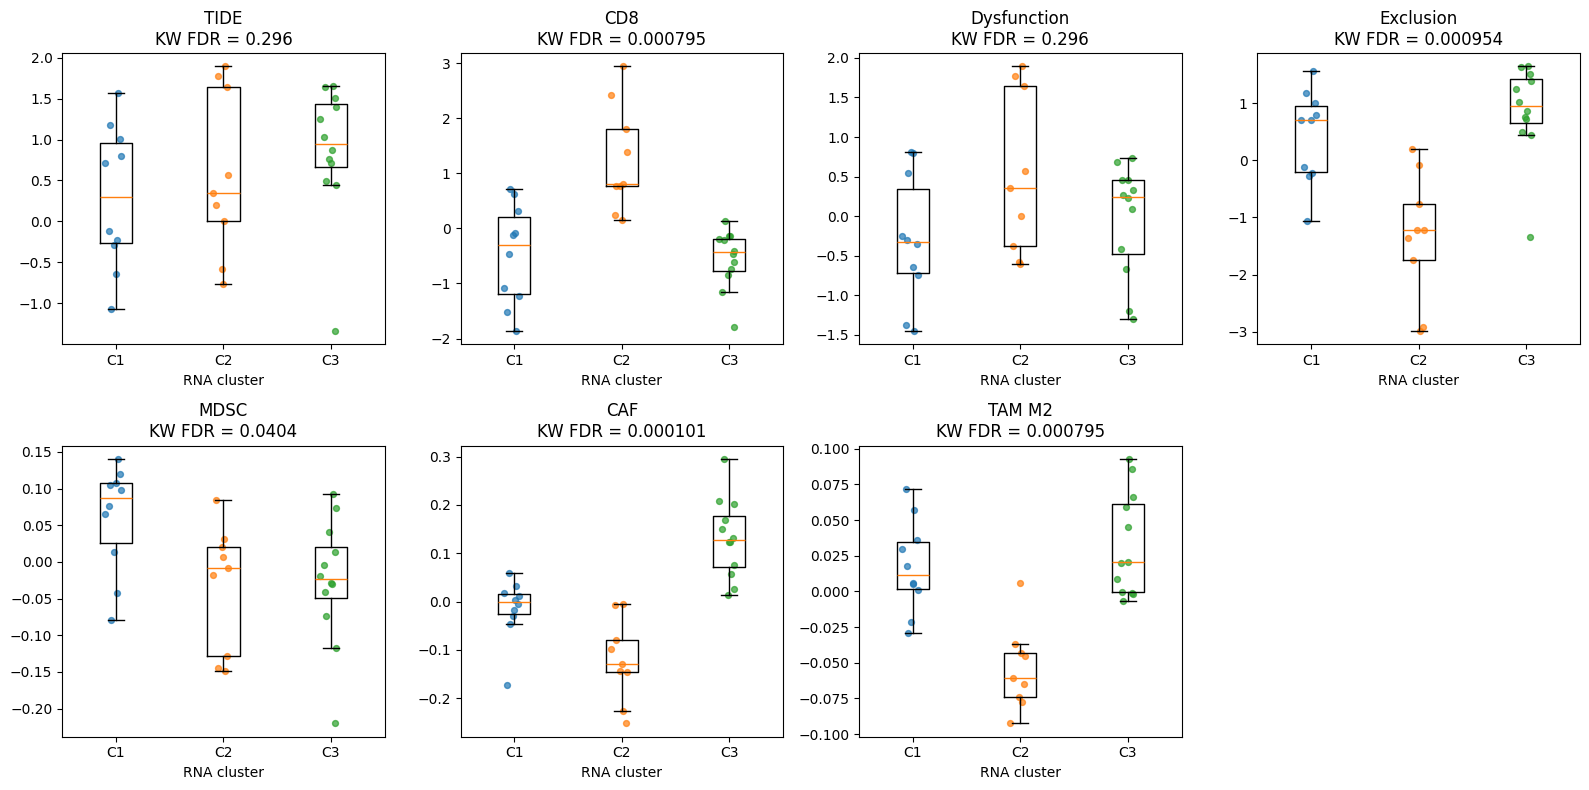

In [7]:
# ---------------- 8. Boxplots with FDR ----------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUT = "/ix1/alee/LO_LAB/Personal/Rahul/pILC/RNASeq/TIDE"

# Load results saved by steps 1-7
tide  = pd.read_csv(f"{OUT}/TIDE_scores_with_clusters.csv")
stats = pd.read_csv(f"{OUT}/TIDE_cluster_statistics.csv")

# Benjamini-Hochberg FDR
def bh(p):
    p = np.asarray(p, dtype=float); n = len(p); o = np.argsort(p)
    q = np.empty(n)
    q[o] = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.minimum(q, 1)

# FDR across the overall Kruskal tests (one value per score), added to the stats file if missing
if "FDR_kruskal" not in stats.columns:
    kw_tab = stats[["score", "p_kruskal_overall"]].drop_duplicates("score").copy()
    kw_tab["FDR_kruskal"] = bh(kw_tab["p_kruskal_overall"])
    stats = stats.merge(kw_tab[["score", "FDR_kruskal"]], on="score")
    stats.to_csv(f"{OUT}/TIDE_cluster_statistics.csv", index=False)

score_cols = list(stats["score"].unique())
clusters   = sorted(tide["cluster"].unique())

n = len(score_cols); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 4 * nrow), squeeze=False)
for ax, sc in zip(axes.flat, score_cols):
    data = [tide.loc[tide.cluster == k, sc].dropna() for k in clusters]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(clusters) + 1))
    ax.set_xticklabels([f"C{k}" for k in clusters])
    for i, d in enumerate(data, start=1):               # show every sample
        ax.scatter(np.random.default_rng(42).normal(i, 0.05, len(d)), d, s=18, alpha=0.7)
    fdr = stats.loc[stats.score == sc, "FDR_kruskal"].iloc[0]
    ax.set_title(f"{sc}\nKW FDR = {fdr:.3g}")               # FDR shown instead of raw p
    ax.set_xlabel("RNA cluster")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT}/TIDE_scores_by_cluster.png", dpi=300)
plt.savefig(f"{OUT}/TIDE_scores_by_cluster.pdf")
display(fig)      
plt.close(fig)   